# 1. Your first campaign

This notebook runs a complete adaptive campaign on a cheap analytic stand-in for an orbit-superposition model,
in a few seconds, and walks through what each stage does:

1. define the **search space** (bounds, log axes, fixed parameters);
2. write the **model**: anything that returns χ² for a table of parameter sets;
3. **run** the campaign: a Sobol design, search rounds by Expected Improvement until the stopping rule fires,
   then error-bar rounds;
4. read the **status** and the **posterior**.

Nothing here is specific to Schwarzschild modeling: replace `toy_model` by your own code and the rest is
unchanged. For codes that run one model per cluster job, see notebook 2.

In [1]:
import numpy as np
import pandas as pd
import sagari as sg
from sagari import posterior as po
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "legend.frameon": False})
INK, BLUE, ORANGE, GRAY = "#222222", "#2a78d6", "#eb6834", "#9a9a9a"
UPS, MBH = r"$\Upsilon$", r"$M_\bullet$"
print("SAGARI", sg.__version__)

SAGARI 1.0.0


## The search space

Free parameters get bounds and an axis: a **log** axis for anything that spans decades (black hole mass, halo
core radius), a linear one otherwise. Everything the method does (the design, the surrogate, distances) happens
in the unit cube these axes define, so the choice of axis is also a choice of prior. Fixed parameters are carried
into every model unchanged.

In [2]:
space = sg.ParameterSpace.from_dict({"name": "toy", "parameters": {
    "mbh":         {"bounds": [1e6, 1e10], "scale": "log"},   # black hole mass [Msun]
    "upsilon":     {"bounds": [1.0, 10.0]},                   # stellar M/L
    "v_c":         {"bounds": [0.0, 500.0]},                  # halo circular velocity [km/s]
    "inclination": {"value": 60.0},                           # fixed
}})
space

ParameterSpace(toy: mbh[1e+06, 1e+10, log], upsilon[1, 10], v_c[0, 500]; fixed inclination=60)

## The model

A stand-in for an orbit-superposition fit: a valley in which a heavier black hole trades against a lower
mass-to-light ratio, a halo the data barely constrain, **model-to-model scatter** of σ = 5 in χ² (the roughness
every real orbit library has), and a corner of the box where models **fail** (χ² = NaN), as models do when the
library cannot reproduce the light.

The true minimum is at M_BH = 2×10⁸, Υ = 6.

In [3]:
TRUTH = {"mbh": 10**8.3, "upsilon": 6.0}

def toy_model(design, sigma=5.0):
    x = np.log10(design["mbh"].values) - 8.3
    y = design["upsilon"].values - 6.0
    z = (design["v_c"].values - 200.0) / 300.0
    chi2 = 1000 + 60 * (x + 0.3 * y) ** 2 + 8 * y ** 2 + 5 * z ** 2
    chi2 += np.random.default_rng(len(design) + int(1e3 * design["upsilon"].sum())).normal(0, sigma, len(chi2))
    chi2[(design["upsilon"].values > 9) & (design["v_c"].values > 400)] = np.nan     # failed models
    return chi2

## Run it

`Campaign.create` writes the campaign to a directory (round files, Sobol state, a log), so a campaign can always
be continued later. The defaults are those of the paper for four parameters (256 initial points, rounds of 128);
for this three-parameter toy we use 64 and 32. `converge_on` names the parameters the stopping rule watches; a
nuisance parameter such as the halo may stay broad.

In [4]:
c = sg.Campaign.create("toy_campaign", space, overwrite=True, n_initial=64, n_round=32,
                        converge_on=["mbh", "upsilon"], errorbars={"n_round": 32, "n_profile": 4})
results = c.run(toy_model)

ParameterSpace(toy: mbh[1e+06, 1e+10, log], upsilon[1, 10], v_c[0, 500]; fixed inclination=60)
4 rounds, 160 models proposed, 160 evaluated (1 failed, 0 outside the current box)
  round 0 (64 models): mbh 1.084e+08-4.721e+08; upsilon 5.342-6.664; chi2_min 996.7, T 4.0
  round 1 (96 models): mbh 8.644e+07-5.289e+08; upsilon 5.213-6.776; chi2_min 999.9, T 4.9  moves {'mbh': 0.125, 'upsilon': 0.083}
  round 2 (128 models): mbh 8.281e+07-5.011e+08; upsilon 5.251-6.813; chi2_min 999.2, T 5.0  moves {'mbh': 0.03, 'upsilon': 0.024}  -> stopping rule met
  error-bar round 3: out-of-sample rms z 1.02 over 32 models (6.2% above +2, 0.0% below -2); worst latent sd 2.03 (tol 3.0), worst end move 0.036  -> done
next: done


The status shows, for every search round, the smoothed 16–84% range of each watched parameter and how far
its ends moved since the previous round (in units of its width). The search stopped when both moved by less than
0.2, after at least two refinement rounds. The error-bar round then tested the surrogate on models it had not
seen: an rms of the standardized residuals near 1 means it predicts new models to within the scatter.

In [5]:
st = c.status(results, verbose=False)
pd.DataFrame([{"round": h["round"], "models": h["n_models"],
               "M_BH 16-84%": f"{h['estimate']['mbh'][1]:.3g} - {h['estimate']['mbh'][2]:.3g}",
               "Upsilon 16-84%": f"{h['estimate']['upsilon'][1]:.3g} - {h['estimate']['upsilon'][2]:.3g}",
               "moves": h.get("moves"), "stop": h["converged"]} for h in st["history"]])

,round,models,M_BH 16-84%,Upsilon 16-84%,moves,stop
0,0,64,1.08e+08 - 4.72e+08,5.34 - 6.66,None,False
1,1,96,8.64e+07 - 5.29e+08,5.21 - 6.78,"{'mbh': 0.125, 'upsilon': 0.083}",False
2,2,128,8.28e+07 - 5.01e+08,5.25 - 6.81,"{'mbh': 0.03, 'upsilon': 0.024}",True


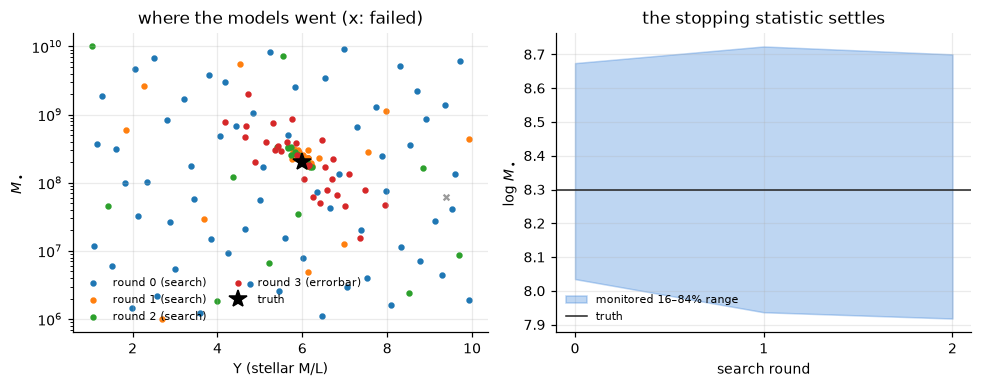

In [6]:
props = c.proposals()
j = c.results_table(results)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
for r, g in j.groupby("round"):
    ok = g["chi2"].notna()
    ax[0].scatter(g.loc[ok, "upsilon"], g.loc[ok, "mbh"], s=10, label=f"round {r} ({g['phase'].iloc[0]})")
    ax[0].scatter(g.loc[~ok, "upsilon"], g.loc[~ok, "mbh"], s=14, marker="x", color=GRAY)
ax[0].plot(TRUTH["upsilon"], TRUTH["mbh"], "k*", ms=12, label="truth")
ax[0].set(yscale="log", xlabel=UPS + " (stellar M/L)", ylabel=MBH, title="where the models went (x: failed)")
ax[0].legend(fontsize=7, ncol=2)
rounds = [h["round"] for h in st["history"]]
lo =[np.log10(h["estimate"]["mbh"][1]) for h in st["history"]]; hi = [np.log10(h["estimate"]["mbh"][2]) for h in st["history"]]
ax[1].fill_between(rounds, lo, hi, color=BLUE, alpha=0.3, label="monitored 16–84% range")
ax[1].axhline(8.3, color=INK, lw=1, label="truth")
ax[1].set(xlabel="search round", ylabel="log " + MBH, title="the stopping statistic settles", xticks=rounds)
ax[1].legend(fontsize=7)
plt.tight_layout()

## The posterior

The constraints come from the final **surrogate**, not from the lowest model: with scatter in χ², the lowest of
many models is systematically too low. The plug-in posterior samples exp(−μ/2) of the surrogate mean, restricted
to where models constrain it. The *surrogate-marginalized* posterior additionally averages over the surrogate's
own uncertainty, by reweighting the samples with joint draws of its latent error.

In [7]:
gp, _, _ = c.surrogate(results)
print(f"surrogate fitted to {len(gp.gp.y_train_)} models; model-to-model scatter sigma_chi2 = {gp.scatter:.1f} (true 5)")
post = po.sample_posterior(gp, space, nsteps=6000, burn=1000)
idx, D, _ = po.surface_draws(gp, post.attrs["unit"], n_sub=1500, n_latent=500, n_refit=0)
rows = []
for p in ("mbh", "upsilon", "v_c"):
    m, lo, hi = np.percentile(post[p], [50, 15.85, 84.15])
    lo2, m2, hi2 = po.pooled_quantiles(post[p].values[idx], D)
    rows.append(dict(param=p, plug_in=f"{m:.4g} [{lo:.4g}, {hi:.4g}]", marginalized=f"{m2:.4g} [{lo2:.4g}, {hi2:.4g}]",
                     truth=TRUTH.get(p, "-")))
pd.DataFrame(rows)

surrogate fitted to 123 models; model-to-model scatter sigma_chi2 = 5.2 (true 5)


,param,plug_in,marginalized,truth
0,mbh,"2.113e+08 [1.346e+08, 3.248e+08]","2.09e+08 [1.3e+08, 3.286e+08]",199526231.496888
1,upsilon,"5.997 [5.622, 6.37]","6.006 [5.601, 6.379]",6.0
2,v_c,"167 [61.21, 294.3]","159.5 [50.06, 293.7]",-


160 models in total


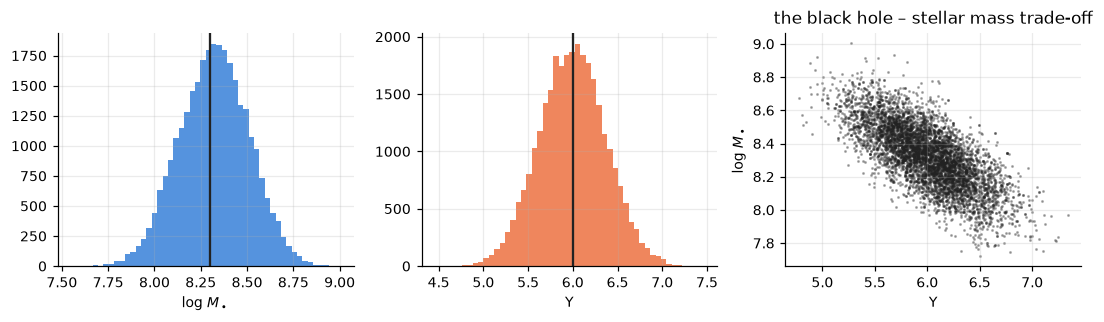

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(10, 3))
ax[0].hist(np.log10(post["mbh"]), 50, color=BLUE, alpha=0.8); ax[0].axvline(8.3, color=INK); ax[0].set_xlabel("log " + MBH)
ax[1].hist(post["upsilon"], 50, color=ORANGE, alpha=0.8); ax[1].axvline(6.0, color=INK); ax[1].set_xlabel(UPS)
ax[2].scatter(post["upsilon"][::5], np.log10(post["mbh"][::5]), s=1, alpha=0.3, color=INK)
ax[2].set(xlabel=UPS, ylabel="log " + MBH, title="the black hole – stellar mass trade-off")
plt.tight_layout()
print(f"{len(results)} models in total")

**Next:** notebook 2 runs the same kind of campaign the way you would on a cluster, one round file at a
time; notebook 3 goes deeper into the analysis of the final surrogate; notebook 4 reproduces the paper's
benchmark and shows how to replay a campaign on an archive of existing models.